In [1]:
%pip install pandas numpy matplotlib seaborn


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nFiles and folders available:")
print(os.listdir())

Current working directory:
c:\Users\User\Desktop\AI_PRO

Files and folders available:
['.venv', '.venv-1', '.venv-2', 'dataset', 'python1.ipynb', 'README.md']


In [4]:
hospitals = pd.read_csv("dataset/hospitals_master.csv")
services = pd.read_csv("dataset/hospital_services.csv")
status = pd.read_csv("dataset/hospital_status_synthetic.csv")
travel = pd.read_csv("dataset/travel_history_synthetic.csv")
scenarios = pd.read_csv("dataset/emergency_test_scenarios.csv")

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [5]:
print("Hospitals:", hospitals.shape)
print("Services:", services.shape)
print("Status:", status.shape)
print("Travel:", travel.shape)
print("Scenarios:", scenarios.shape)

Hospitals: (15, 17)
Services: (66, 4)
Status: (1800, 7)
Travel: (2000, 9)
Scenarios: (300, 7)


In [6]:
print(hospitals.head())

  hosp_id                                 facility  fac_type  \
0   BH001                          Varma Hospitals  Hospital   
1   BH002                Bhimavaram Hospitals Ltd.  Hospital   
2   BH003                       Imperial Hospitals  Hospital   
3   BH004          Rajarshi Hospitals - Bhimavaram  Hospital   
4   BH005  Nallaparaju Venkata Raju (NVR) Hospital  Hospital   

                ownership        area  \
0  Private multispecialty  Bhimavaram   
1  Private multispecialty  Bhimavaram   
2  Private multispecialty  Bhimavaram   
3  Private multispecialty  Bhimavaram   
4  Private multispecialty  Bhimavaram   

                                             address        lat        lon  \
0  D.No. 1-7-4/2-1, Suryanarayana Puram, J.P. Roa...  16.544090  81.510385   
1                       J.P. Road, Bhimavaram 534204  16.541201  81.496051   
2        Sivaraopeta, Balusumoodi, Bhimavaram 534202  16.542761  81.512808   
3  2-15-30, Sri Mavulamma Ammavari Complex, Undi ...  16

In [7]:
# 1. Hospitals dataset
hospitals.rename(columns={
    "hospital_id": "hosp_id",
    "facility_name": "facility",
    "facility_type": "fac_type",
    "ownership_and_level": "ownership",
    "area": "area",
    "address": "address",
    "latitude": "lat",
    "longitude": "lon",
    "source_verification_level": "verify_level",
    "emergency_capability_public_info": "emergency_info",
    "publicly_listed_services": "listed_services",
    "published_bed_capacity": "bed_capacity",
    "ambulance_service_public_info": "ambulance_info",
    "live_capacity_status": "live_status",
    "source_url": "source_url",
    "source_type": "source_type",
    "verification_notes": "verify_notes"
}, inplace=True)


# 2. Hospital services dataset
services.rename(columns={
    "hospital_id": "hosp_id",
    "service_name": "service",
    "evidence_status": "evidence",
    "notes": "notes"
}, inplace=True)


# 3. Hospital status dataset
status.rename(columns={
    "hospital_id": "hosp_id",
    "demo_date": "date",
    "demo_hour": "hour",
    "simulated_occupancy_pct": "occupancy_pct",
    "simulated_wait_minutes": "wait_min",
    "simulated_emergency_load": "emergency_load",
    "data_type": "data_type"
}, inplace=True)


# 4. Travel dataset
travel.rename(columns={
    "trip_id": "trip_id",
    "origin_zone": "origin",
    "destination_hospital_id": "dest_hosp_id",
    "departure_hour": "depart_hour",
    "day_of_week": "day",
    "simulated_straight_or_assumed_distance_km": "distance_km",
    "simulated_journey_duration_min": "travel_min",
    "data_type": "data_type",
    "warning": "warning"
}, inplace=True)


# 5. Emergency scenarios dataset
scenarios.rename(columns={
    "scenario_id": "scenario_id",
    "origin_zone": "origin",
    "emergency_category": "emergency",
    "departure_hour": "depart_hour",
    "day_type": "day_type",
    "data_type": "data_type",
    "warning": "warning"
}, inplace=True)

print("All column names renamed successfully!")

All column names renamed successfully!


C:\Users\User\AppData\Local\Temp\ipykernel_38356\2535896670.py:2: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  hospitals.rename(columns={
C:\Users\User\AppData\Local\Temp\ipykernel_38356\2535896670.py:24: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  services.rename(columns={
C:\Users\User\AppData\Local\Temp\ipykernel_38356\2535896670.py:33: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  status.rename(columns={
C:\Users\User\AppData\Local\Temp\ipykernel_38356\2535896670.py:

In [8]:
datasets = {
    "hospitals": hospitals,
    "services": services,
    "status": status,
    "travel": travel,
    "scenarios": scenarios
}

In [9]:
for name, df in datasets.items():
    print(f"\n{name.upper()}")
    print(df.columns.tolist())


HOSPITALS
['hosp_id', 'facility', 'fac_type', 'ownership', 'area', 'address', 'lat', 'lon', 'verify_level', 'emergency_info', 'listed_services', 'bed_capacity', 'ambulance_info', 'live_status', 'source_url', 'source_type', 'verify_notes']

SERVICES
['hosp_id', 'service', 'evidence', 'notes']

STATUS
['hosp_id', 'date', 'hour', 'occupancy_pct', 'wait_min', 'emergency_load', 'data_type']

TRAVEL
['trip_id', 'origin', 'dest_hosp_id', 'depart_hour', 'day', 'distance_km', 'travel_min', 'data_type', 'warning']

SCENARIOS
['scenario_id', 'origin', 'emergency', 'depart_hour', 'day_type', 'data_type', 'warning']


In [10]:
for name, df in datasets.items():
    print(f"\n========== {name.upper()} ==========")
    print(df.dtypes)


========== HOSPITALS ==========
hosp_id                str
facility               str
fac_type               str
ownership              str
area                   str
address                str
lat                float64
lon                float64
verify_level           str
emergency_info         str
listed_services        str
bed_capacity           str
ambulance_info         str
live_status            str
source_url             str
source_type            str
verify_notes           str
dtype: object

========== SERVICES ==========
hosp_id     str
service     str
evidence    str
notes       str
dtype: object

========== STATUS ==========
hosp_id             str
date                str
hour              int64
occupancy_pct     int64
wait_min          int64
emergency_load      str
data_type           str
dtype: object

========== TRAVEL ==========
trip_id             str
origin              str
dest_hosp_id        str
depart_hour       int64
day                 str
distance_km     float6

In [11]:
for name, df in datasets.items():
    print(f"\n========== {name.upper()} ==========")
    print(df.isnull().sum())


========== HOSPITALS ==========
hosp_id            0
facility           0
fac_type           0
ownership          0
area               0
address            0
lat                0
lon                0
verify_level       0
emergency_info     0
listed_services    0
bed_capacity       0
ambulance_info     0
live_status        0
source_url         8
source_type        0
verify_notes       0
dtype: int64

========== SERVICES ==========
hosp_id     0
service     0
evidence    0
notes       0
dtype: int64

========== STATUS ==========
hosp_id           0
date              0
hour              0
occupancy_pct     0
wait_min          0
emergency_load    0
data_type         0
dtype: int64

========== TRAVEL ==========
trip_id         0
origin          0
dest_hosp_id    0
depart_hour     0
day             0
distance_km     0
travel_min      0
data_type       0
warning         0
dtype: int64

========== SCENARIOS ==========
scenario_id    0
origin         0
emergency      0
depart_hour    0
day_typ

In [12]:
for name, df in datasets.items():
    print(f"\n========== {name.upper()} ==========")
    print("Duplicate rows:", df.duplicated().sum())


========== HOSPITALS ==========
Duplicate rows: 0

========== SERVICES ==========
Duplicate rows: 0

========== STATUS ==========
Duplicate rows: 0

========== TRAVEL ==========
Duplicate rows: 0

========== SCENARIOS ==========
Duplicate rows: 0


In [13]:
for name, df in datasets.items():
    print(f"\n========== {name.upper()} ==========")
    display(df.describe(include="all"))


========== HOSPITALS ==========


,hosp_id,facility,fac_type,ownership,area,address,lat,lon,verify_level,emergency_info,listed_services,bed_capacity,ambulance_info,live_status,source_url,source_type,verify_notes
count,15,15,15,15,15,15,15.000000,15.000000,15,15,15,15,15,15,7,15,15
unique,15,15,2,5,3,15,NaN,NaN,8,8,14,5,2,1,6,9,15
top,BH001,Varma Hospitals,Hospital,Private multispecialty,Bhimavaram,"D.No. 1-7-4/2-1, Suryanarayana Puram, J.P. Roa...",NaN,NaN,Public listing only,Unknown,Unknown - verify with official source,Unknown,Unknown,Unknown - no live feed,https://www.dme.ap.nic.in/leftmenu_pages/ma_me...,Public business listing,Published information only; re-confirm current...
freq,1,1,14,5,13,1,NaN,NaN,6,8,2,11,14,15,2,6,1
mean,NaN,NaN,NaN,NaN,NaN,NaN,16.543710,81.511943,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,0.003001,0.011584,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,16.539999,81.485477,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,16.542157,81.509731,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,16.543015,81.514141,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,16.544277,81.516480,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



========== SERVICES ==========


,hosp_id,service,evidence,notes
count,66,66,66,66
unique,15,26,2,2
top,BH002,Unknown - needs verification,Publicly listed,Service listing is not confirmation of current...
freq,17,9,57,57



========== STATUS ==========


,hosp_id,date,hour,occupancy_pct,wait_min,emergency_load,data_type
count,1800,1800,1800.000000,1800.000000,1800.000000,1800,1800
unique,15,30,NaN,NaN,NaN,3,1
top,BH001,2026-10-01,NaN,NaN,NaN,Moderate,SYNTHETIC_DEMO_ONLY
freq,120,60,NaN,NaN,NaN,615,1800
mean,NaN,NaN,9.000000,60.845000,46.738889,NaN,NaN
std,NaN,NaN,6.710068,20.903332,24.759626,NaN,NaN
min,NaN,NaN,0.000000,25.000000,5.000000,NaN,NaN
25%,NaN,NaN,4.500000,43.000000,25.000000,NaN,NaN
50%,NaN,NaN,9.000000,61.000000,46.000000,NaN,NaN
75%,NaN,NaN,13.500000,79.000000,68.000000,NaN,NaN



========== TRAVEL ==========


,trip_id,origin,dest_hosp_id,depart_hour,day,distance_km,travel_min,data_type,warning
count,2000,2000,2000,2000.000000,2000,2000.00000,2000.000000,2000,2000
unique,2000,8,14,NaN,7,NaN,NaN,1,1
top,SIM00001,Bhimavaram_North,BH004,NaN,Tuesday,NaN,NaN,SYNTHETIC_DEMO_ONLY,Generated formula + random noise; do not use a...
freq,1,261,156,NaN,304,NaN,NaN,2000,2000
mean,NaN,NaN,NaN,11.222500,NaN,6.15526,17.103500,NaN,NaN
std,NaN,NaN,NaN,6.962559,NaN,3.29083,8.772415,NaN,NaN
min,NaN,NaN,NaN,0.000000,NaN,0.51000,2.000000,NaN,NaN
25%,NaN,NaN,NaN,5.000000,NaN,3.36750,10.000000,NaN,NaN
50%,NaN,NaN,NaN,11.000000,NaN,6.13500,17.000000,NaN,NaN
75%,NaN,NaN,NaN,17.000000,NaN,8.88250,24.000000,NaN,NaN



========== SCENARIOS ==========


,scenario_id,origin,emergency,depart_hour,day_type,data_type,warning
count,300,300,300,300.000000,300,300,300
unique,300,8,7,NaN,2,1,1
top,SC0001,Pedamiram,Chest_Pain,NaN,Weekday,SYNTHETIC_TEST_CASE_ONLY,For software testing only; not a clinical tria...
freq,1,49,49,NaN,151,300,300
mean,NaN,NaN,NaN,11.276667,NaN,NaN,NaN
std,NaN,NaN,NaN,6.980153,NaN,NaN,NaN
min,NaN,NaN,NaN,0.000000,NaN,NaN,NaN
25%,NaN,NaN,NaN,5.000000,NaN,NaN,NaN
50%,NaN,NaN,NaN,12.000000,NaN,NaN,NaN
75%,NaN,NaN,NaN,17.000000,NaN,NaN,NaN


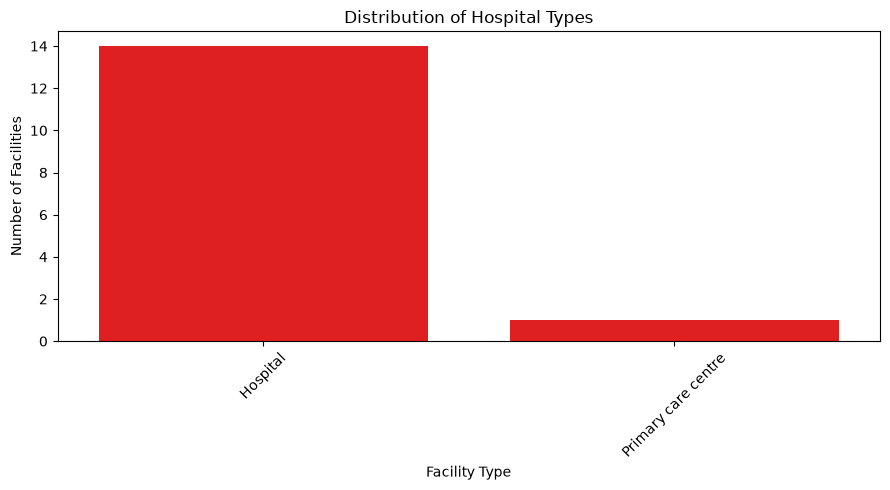

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.countplot(
    data=hospitals,
    x="fac_type",
    color="red"
)

plt.title("Distribution of Hospital Types")
plt.xlabel("Facility Type")
plt.ylabel("Number of Facilities")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

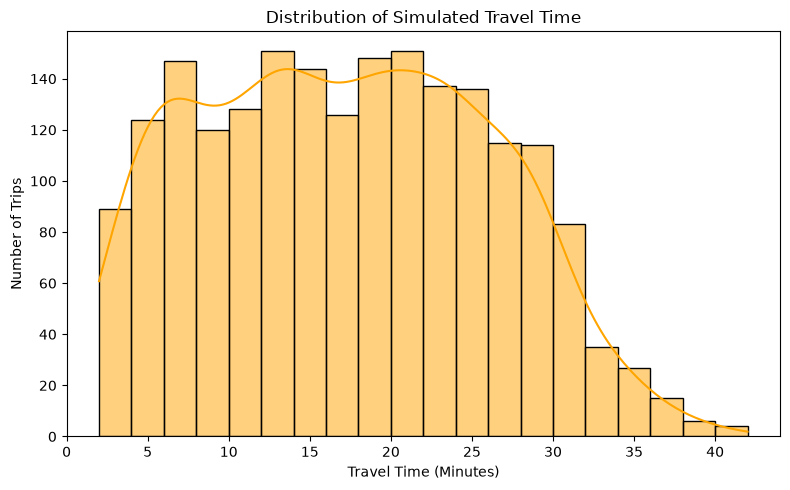

In [15]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=travel,
    x="travel_min",
    bins=20,
    kde=True,
    color="orange"
)

plt.title("Distribution of Simulated Travel Time")
plt.xlabel("Travel Time (Minutes)")
plt.ylabel("Number of Trips")

plt.tight_layout()
plt.show()

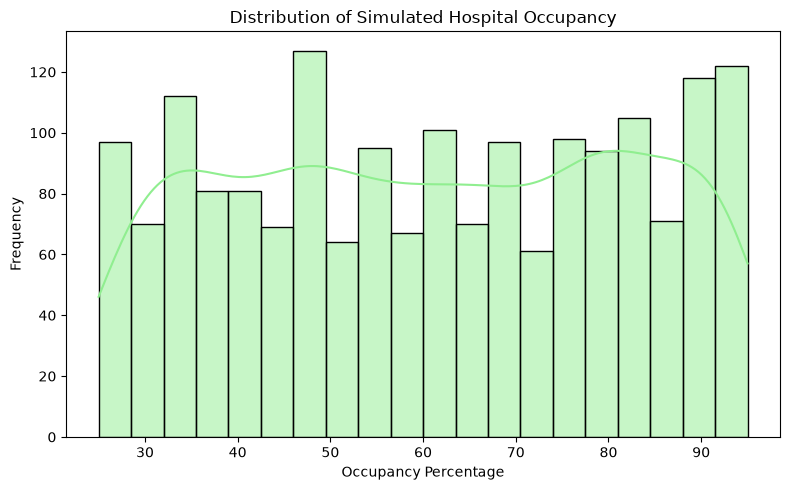

In [16]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=status,
    x="occupancy_pct",
    bins=20,
    kde=True,
    color="lightgreen"
)

plt.title("Distribution of Simulated Hospital Occupancy")
plt.xlabel("Occupancy Percentage")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [17]:
print("Total hospitals:", len(hospitals))

print("Unique hospital IDs:",
      hospitals["hosp_id"].nunique())

print("Unique facilities:",
      hospitals["facility"].nunique())

Total hospitals: 15
Unique hospital IDs: 15
Unique facilities: 15


In [18]:
hospitals[hospitals["hosp_id"].duplicated(keep=False)] #shows duplicate hospital IDs 

,hosp_id,facility,fac_type,ownership,area,address,lat,lon,verify_level,emergency_info,listed_services,bed_capacity,ambulance_info,live_status,source_url,source_type,verify_notes


In [19]:
hospital_services = pd.merge(
    hospitals,
    services,
    on="hosp_id",
    how="left"
)

display(hospital_services.head())

,hosp_id,facility,fac_type,ownership,area,address,lat,lon,verify_level,emergency_info,listed_services,bed_capacity,ambulance_info,live_status,source_url,source_type,verify_notes,service,evidence,notes
0,BH001,Varma Hospitals,Hospital,Private multispecialty,Bhimavaram,"D.No. 1-7-4/2-1, Suryanarayana Puram, J.P. Roa...",16.54409,81.510385,Verified from hospital website,Casualty/emergency doctors round the clock sta...,Cardiology; Cardiothoracic Surgery; Urology; N...,100 inpatient beds stated; not live vacant beds,24-hour ambulance stated,Unknown - no live feed,https://www.varmahospitals.com/content/services,Official hospital website; AP DME recognized list,Published information only; re-confirm current...,Cardiology,Publicly listed,Service listing is not confirmation of current...
1,BH001,Varma Hospitals,Hospital,Private multispecialty,Bhimavaram,"D.No. 1-7-4/2-1, Suryanarayana Puram, J.P. Roa...",16.54409,81.510385,Verified from hospital website,Casualty/emergency doctors round the clock sta...,Cardiology; Cardiothoracic Surgery; Urology; N...,100 inpatient beds stated; not live vacant beds,24-hour ambulance stated,Unknown - no live feed,https://www.varmahospitals.com/content/services,Official hospital website; AP DME recognized list,Published information only; re-confirm current...,Cardiothoracic Surgery,Publicly listed,Service listing is not confirmation of current...
2,BH001,Varma Hospitals,Hospital,Private multispecialty,Bhimavaram,"D.No. 1-7-4/2-1, Suryanarayana Puram, J.P. Roa...",16.54409,81.510385,Verified from hospital website,Casualty/emergency doctors round the clock sta...,Cardiology; Cardiothoracic Surgery; Urology; N...,100 inpatient beds stated; not live vacant beds,24-hour ambulance stated,Unknown - no live feed,https://www.varmahospitals.com/content/services,Official hospital website; AP DME recognized list,Published information only; re-confirm current...,Urology,Publicly listed,Service listing is not confirmation of current...
3,BH001,Varma Hospitals,Hospital,Private multispecialty,Bhimavaram,"D.No. 1-7-4/2-1, Suryanarayana Puram, J.P. Roa...",16.54409,81.510385,Verified from hospital website,Casualty/emergency doctors round the clock sta...,Cardiology; Cardiothoracic Surgery; Urology; N...,100 inpatient beds stated; not live vacant beds,24-hour ambulance stated,Unknown - no live feed,https://www.varmahospitals.com/content/services,Official hospital website; AP DME recognized list,Published information only; re-confirm current...,Neurosurgery,Publicly listed,Service listing is not confirmation of current...
4,BH001,Varma Hospitals,Hospital,Private multispecialty,Bhimavaram,"D.No. 1-7-4/2-1, Suryanarayana Puram, J.P. Roa...",16.54409,81.510385,Verified from hospital website,Casualty/emergency doctors round the clock sta...,Cardiology; Cardiothoracic Surgery; Urology; N...,100 inpatient beds stated; not live vacant beds,24-hour ambulance stated,Unknown - no live feed,https://www.varmahospitals.com/content/services,Official hospital website; AP DME recognized list,Published information only; re-confirm current...,General Medicine,Publicly listed,Service listing is not confirmation of current...


In [20]:
hospital_services.head()

,hosp_id,facility,fac_type,ownership,area,address,lat,lon,verify_level,emergency_info,listed_services,bed_capacity,ambulance_info,live_status,source_url,source_type,verify_notes,service,evidence,notes
0,BH001,Varma Hospitals,Hospital,Private multispecialty,Bhimavaram,"D.No. 1-7-4/2-1, Suryanarayana Puram, J.P. Roa...",16.54409,81.510385,Verified from hospital website,Casualty/emergency doctors round the clock sta...,Cardiology; Cardiothoracic Surgery; Urology; N...,100 inpatient beds stated; not live vacant beds,24-hour ambulance stated,Unknown - no live feed,https://www.varmahospitals.com/content/services,Official hospital website; AP DME recognized list,Published information only; re-confirm current...,Cardiology,Publicly listed,Service listing is not confirmation of current...
1,BH001,Varma Hospitals,Hospital,Private multispecialty,Bhimavaram,"D.No. 1-7-4/2-1, Suryanarayana Puram, J.P. Roa...",16.54409,81.510385,Verified from hospital website,Casualty/emergency doctors round the clock sta...,Cardiology; Cardiothoracic Surgery; Urology; N...,100 inpatient beds stated; not live vacant beds,24-hour ambulance stated,Unknown - no live feed,https://www.varmahospitals.com/content/services,Official hospital website; AP DME recognized list,Published information only; re-confirm current...,Cardiothoracic Surgery,Publicly listed,Service listing is not confirmation of current...
2,BH001,Varma Hospitals,Hospital,Private multispecialty,Bhimavaram,"D.No. 1-7-4/2-1, Suryanarayana Puram, J.P. Roa...",16.54409,81.510385,Verified from hospital website,Casualty/emergency doctors round the clock sta...,Cardiology; Cardiothoracic Surgery; Urology; N...,100 inpatient beds stated; not live vacant beds,24-hour ambulance stated,Unknown - no live feed,https://www.varmahospitals.com/content/services,Official hospital website; AP DME recognized list,Published information only; re-confirm current...,Urology,Publicly listed,Service listing is not confirmation of current...
3,BH001,Varma Hospitals,Hospital,Private multispecialty,Bhimavaram,"D.No. 1-7-4/2-1, Suryanarayana Puram, J.P. Roa...",16.54409,81.510385,Verified from hospital website,Casualty/emergency doctors round the clock sta...,Cardiology; Cardiothoracic Surgery; Urology; N...,100 inpatient beds stated; not live vacant beds,24-hour ambulance stated,Unknown - no live feed,https://www.varmahospitals.com/content/services,Official hospital website; AP DME recognized list,Published information only; re-confirm current...,Neurosurgery,Publicly listed,Service listing is not confirmation of current...
4,BH001,Varma Hospitals,Hospital,Private multispecialty,Bhimavaram,"D.No. 1-7-4/2-1, Suryanarayana Puram, J.P. Roa...",16.54409,81.510385,Verified from hospital website,Casualty/emergency doctors round the clock sta...,Cardiology; Cardiothoracic Surgery; Urology; N...,100 inpatient beds stated; not live vacant beds,24-hour ambulance stated,Unknown - no live feed,https://www.varmahospitals.com/content/services,Official hospital website; AP DME recognized list,Published information only; re-confirm current...,General Medicine,Publicly listed,Service listing is not confirmation of current...


In [21]:
hospital_services.shape

(66, 20)

In [22]:
unmatched_services = services[
    ~services["hosp_id"].isin(hospitals["hosp_id"])
]

print("Unmatched service records:", len(unmatched_services))

display(unmatched_services)

Unmatched service records: 0


,hosp_id,service,evidence,notes


In [23]:
print("Duplicate hospital IDs:",
      hospitals["hosp_id"].duplicated().sum())

print("Duplicate service records:",
      services.duplicated().sum())

Duplicate hospital IDs: 0
Duplicate service records: 0


In [24]:
missing_values = hospital_services.isnull().sum()

print(missing_values)

hosp_id            0
facility           0
fac_type           0
ownership          0
area               0
address            0
lat                0
lon                0
verify_level       0
emergency_info     0
listed_services    0
bed_capacity       0
ambulance_info     0
live_status        0
source_url         8
source_type        0
verify_notes       0
service            0
evidence           0
notes              0
dtype: int64


In [25]:
print("Missing Latitude:", hospitals["lat"].isnull().sum())

print("Missing Longitude:", hospitals["lon"].isnull().sum())

display(
    hospitals[["hosp_id", "facility", "lat", "lon"]]
)

Missing Latitude: 0
Missing Longitude: 0


,hosp_id,facility,lat,lon
0,BH001,Varma Hospitals,16.544090,81.510385
1,BH002,Bhimavaram Hospitals Ltd.,16.541201,81.496051
2,BH003,Imperial Hospitals,16.542761,81.512808
3,BH004,Rajarshi Hospitals - Bhimavaram,16.552981,81.509078
4,BH005,Nallaparaju Venkata Raju (NVR) Hospital,16.542578,81.514141
5,BH006,Vinayaka Hospital,16.544883,81.515859
6,BH007,Sri Lakshmi Hospitals,16.545727,81.519323
7,BH008,Akshara Speciality Hospitals,16.541736,81.501345
8,BH009,R.K. Gayathri Hospital,16.544182,81.510758
9,BH010,"Motherness Fertility, Women & Children's Hospital",16.542678,81.514552


In [26]:
display(
    hospitals[["hosp_id", "facility", "address", "lat", "lon"]]
)

,hosp_id,facility,address,lat,lon
0,BH001,Varma Hospitals,"D.No. 1-7-4/2-1, Suryanarayana Puram, J.P. Roa...",16.544090,81.510385
1,BH002,Bhimavaram Hospitals Ltd.,"J.P. Road, Bhimavaram 534204",16.541201,81.496051
2,BH003,Imperial Hospitals,"Sivaraopeta, Balusumoodi, Bhimavaram 534202",16.542761,81.512808
3,BH004,Rajarshi Hospitals - Bhimavaram,"2-15-30, Sri Mavulamma Ammavari Complex, Undi ...",16.552981,81.509078
4,BH005,Nallaparaju Venkata Raju (NVR) Hospital,"24-14-6, Sri Abhiruchi Hotel Canal Road, Juvva...",16.542578,81.514141
5,BH006,Vinayaka Hospital,"2-6-2, Nadipalli Vari Street, J.P. Road, Bhima...",16.544883,81.515859
6,BH007,Sri Lakshmi Hospitals,"Town Station Road, Balusumoodi, Bhimavaram 534202",16.545727,81.519323
7,BH008,Akshara Speciality Hospitals,"Juvvalapalem Road, Tammi Raju Nagar, Chinamira...",16.541736,81.501345
8,BH009,R.K. Gayathri Hospital,"Juvvalapalem Road, Suryanarayana Puram, Bhimav...",16.544182,81.510758
9,BH010,"Motherness Fertility, Women & Children's Hospital","Ranga Raju Elite, BJP Office Road, Sriramapura...",16.542678,81.514552


In [27]:
print(hospitals[["hosp_id", "facility", "address"]].to_string(index=False))

hosp_id                                          facility                                                                       address
  BH001                                   Varma Hospitals            D.No. 1-7-4/2-1, Suryanarayana Puram, J.P. Road, Bhimavaram 534202
  BH002                         Bhimavaram Hospitals Ltd.                                                  J.P. Road, Bhimavaram 534204
  BH003                                Imperial Hospitals                                   Sivaraopeta, Balusumoodi, Bhimavaram 534202
  BH004                   Rajarshi Hospitals - Bhimavaram         2-15-30, Sri Mavulamma Ammavari Complex, Undi Road, Bhimavaram 534206
  BH005           Nallaparaju Venkata Raju (NVR) Hospital 24-14-6, Sri Abhiruchi Hotel Canal Road, Juvvalapalem Road, Bhimavaram 534202
  BH006                                 Vinayaka Hospital                    2-6-2, Nadipalli Vari Street, J.P. Road, Bhimavaram 534202
  BH007                             Sri Lakshmi 

In [28]:
%pip install geopy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [29]:
from geopy.geocoders import Nominatim
geolocator = Nominatim(user_agent="emergency_routing_project")
location = geolocator.geocode(
    "Varma Hospitals, Bhimavaram, Andhra Pradesh, India"
)

if location:
    print("Latitude:", location.latitude)
    print("Longitude:", location.longitude)
    print("Matched address:", location.address)
else:
    print("Location not found")

Latitude: 16.5440896
Longitude: 81.5103849
Matched address: Varma Hospital, Bhimavaram - Gudivada Road, Bhimavaram Urban, Sivaraopeta, Bhimavaram, Bhimavaram Mandal, West Godavari District, Andhra Pradesh, 534201, India


In [30]:
hospitals.loc[
    hospitals["hosp_id"] == "BH001",
    ["lat", "lon"]
] = [16.5440896, 81.5103849]

display(
    hospitals[["hosp_id", "facility", "lat", "lon"]]
)

,hosp_id,facility,lat,lon
0,BH001,Varma Hospitals,16.544090,81.510385
1,BH002,Bhimavaram Hospitals Ltd.,16.541201,81.496051
2,BH003,Imperial Hospitals,16.542761,81.512808
3,BH004,Rajarshi Hospitals - Bhimavaram,16.552981,81.509078
4,BH005,Nallaparaju Venkata Raju (NVR) Hospital,16.542578,81.514141
5,BH006,Vinayaka Hospital,16.544883,81.515859
6,BH007,Sri Lakshmi Hospitals,16.545727,81.519323
7,BH008,Akshara Speciality Hospitals,16.541736,81.501345
8,BH009,R.K. Gayathri Hospital,16.544182,81.510758
9,BH010,"Motherness Fertility, Women & Children's Hospital",16.542678,81.514552


In [31]:
from geopy.extra.rate_limiter import RateLimiter
import pandas as pd

#  Between Nominatim requests 1.1 seconds gap
geocode = RateLimiter(
    geolocator.geocode,
    min_delay_seconds=1.1,
    max_retries=2,
    error_wait_seconds=5
)

results = []

# BH001 already geocoded; remaining 14 only
remaining_hospitals = hospitals[
    hospitals["hosp_id"] != "BH001"
]

for _, row in remaining_hospitals.iterrows():

    query = f"{row['facility']}, Bhimavaram, Andhra Pradesh, India"

    try:
        location = geocode(query, timeout=15)

        if location:
            results.append({
                "hosp_id": row["hosp_id"],
                "facility": row["facility"],
                "latitude": location.latitude,
                "longitude": location.longitude,
                "matched_address": location.address,
                "verification": "Needs Google Maps verification"
            })
        else:
            results.append({
                "hosp_id": row["hosp_id"],
                "facility": row["facility"],
                "latitude": None,
                "longitude": None,
                "matched_address": "Not found",
                "verification": "Manual search required"
            })

    except Exception as e:
        results.append({
            "hosp_id": row["hosp_id"],
            "facility": row["facility"],
            "latitude": None,
            "longitude": None,
            "matched_address": str(e),
            "verification": "Search error"
        })

geocoding_results = pd.DataFrame(results)

display(geocoding_results)

,hosp_id,facility,latitude,longitude,matched_address,verification
0,BH002,Bhimavaram Hospitals Ltd.,NaN,NaN,Not found,Manual search required
1,BH003,Imperial Hospitals,16.542761,81.512808,"Imperial Hospitals, MDR0193, Bhimavaram Urban,...",Needs Google Maps verification
2,BH004,Rajarshi Hospitals - Bhimavaram,NaN,NaN,Not found,Manual search required
3,BH005,Nallaparaju Venkata Raju (NVR) Hospital,NaN,NaN,Not found,Manual search required
4,BH006,Vinayaka Hospital,NaN,NaN,Not found,Manual search required
5,BH007,Sri Lakshmi Hospitals,16.545727,81.519323,"Sri Lakshmi Hospital, NH165, Bhimavaram Urban,...",Needs Google Maps verification
6,BH008,Akshara Speciality Hospitals,16.541736,81.501345,"Akshara Speciality Hospitals, Bhimavaram - Gud...",Needs Google Maps verification
7,BH009,R.K. Gayathri Hospital,NaN,NaN,Not found,Manual search required
8,BH010,"Motherness Fertility, Women & Children's Hospital",NaN,NaN,Not found,Manual search required
9,BH011,Sai Indian Hospitals,16.543015,81.515117,"Sai Indian Hospitals, Bhimavaram - Gudivada Ro...",Needs Google Maps verification


In [32]:
missing_hospitals = hospitals[
    hospitals["hosp_id"].isin(
        geocoding_results.loc[
            geocoding_results["latitude"].isna(),
            "hosp_id"
        ]
    )
]

retry_results = []

for _, row in missing_hospitals.iterrows():

    query = f"{row['address']}, Bhimavaram, Andhra Pradesh, India"

    try:
        location = geocode(query, timeout=15)

        if location:
            retry_results.append({
                "hosp_id": row["hosp_id"],
                "facility": row["facility"],
                "latitude": location.latitude,
                "longitude": location.longitude,
                "matched_address": location.address
            })
        else:
            retry_results.append({
                "hosp_id": row["hosp_id"],
                "facility": row["facility"],
                "latitude": None,
                "longitude": None,
                "matched_address": "Not found"
            })

    except Exception as e:
        retry_results.append({
            "hosp_id": row["hosp_id"],
            "facility": row["facility"],
            "latitude": None,
            "longitude": None,
            "matched_address": str(e)
        })

retry_df = pd.DataFrame(retry_results)

display(retry_df)

,hosp_id,facility,latitude,longitude,matched_address
0,BH002,Bhimavaram Hospitals Ltd.,NaN,NaN,Not found
1,BH004,Rajarshi Hospitals - Bhimavaram,NaN,NaN,Not found
2,BH005,Nallaparaju Venkata Raju (NVR) Hospital,NaN,NaN,Not found
3,BH006,Vinayaka Hospital,NaN,NaN,Not found
4,BH009,R.K. Gayathri Hospital,NaN,NaN,Not found
5,BH010,"Motherness Fertility, Women & Children's Hospital",NaN,NaN,Not found
6,BH012,Mithra Medicare Hospital,NaN,NaN,Not found
7,BH013,Gift Fertility & Neuro Hospital,NaN,NaN,Not found
8,BH014,Area Hospital - Bhimavaram,16.544131,81.529605,"Gandhinagar, Narasa Agraharam, Bhimavaram, Bhi..."


In [33]:
hospitals.loc[
    hospitals["hosp_id"] == "BH002",
    ["lat", "lon"]
] = [16.541201385466795, 81.4960511916474]

In [34]:
display(
    hospitals.loc[
        hospitals["hosp_id"] == "BH002",
        ["hosp_id", "facility", "lat", "lon"]
    ]
)

,hosp_id,facility,lat,lon
1,BH002,Bhimavaram Hospitals Ltd.,16.541201,81.496051


In [35]:
hospitals.loc[
    hospitals["hosp_id"] == "BH004",
    ["lat", "lon"]
] = [16.552981436686323, 81.50907766441757]

In [36]:
hospitals.loc[
    hospitals["hosp_id"] == "BH006",
    ["lat", "lon"]
] = [16.54488313877864, 81.51585927975799]

In [37]:
hospitals.loc[
    hospitals["hosp_id"] == "BH009",
    ["lat", "lon"]
] = [16.544182208767257, 81.51075817975797]

In [38]:
hospitals.loc[
    hospitals["hosp_id"] == "BH010",
    ["lat", "lon"]
] = [16.542678095048657, 81.5145520662633]

In [39]:
hospitals.loc[
    hospitals["hosp_id"] == "BH012",
    ["lat", "lon"]
] = [16.54424780870081, 81.48547712024202]

In [40]:
hospitals.loc[
    hospitals["hosp_id"] == "BH013",
    ["lat", "lon"]
] = [16.54430691304882, 81.51710046329124]

In [41]:
hospitals.loc[
    hospitals["hosp_id"] == "BH014",
    ["lat", "lon"]
] = [16.541265803207665, 81.52053947870125]

In [42]:
coordinates = {
    "BH003": (16.542761, 81.512808),
    "BH007": (16.545727, 81.519323),
    "BH005": (16.5425784, 81.5141411),
    "BH008": (16.541736, 81.501345),
    "BH011": (16.543015, 81.515117),
    "BH015": (16.539999, 81.536610)
}

for hosp_id, (lat, lon) in coordinates.items():

    hospitals.loc[
        hospitals["hosp_id"] == hosp_id,
        ["lat", "lon"]
    ] = [lat, lon]

print("Coordinates updated successfully!")

Coordinates updated successfully!


In [43]:
display(hospitals)

,hosp_id,facility,fac_type,ownership,area,address,lat,lon,verify_level,emergency_info,listed_services,bed_capacity,ambulance_info,live_status,source_url,source_type,verify_notes
0,BH001,Varma Hospitals,Hospital,Private multispecialty,Bhimavaram,"D.No. 1-7-4/2-1, Suryanarayana Puram, J.P. Roa...",16.544090,81.510385,Verified from hospital website,Casualty/emergency doctors round the clock sta...,Cardiology; Cardiothoracic Surgery; Urology; N...,100 inpatient beds stated; not live vacant beds,24-hour ambulance stated,Unknown - no live feed,https://www.varmahospitals.com/content/services,Official hospital website; AP DME recognized list,Published information only; re-confirm current...
1,BH002,Bhimavaram Hospitals Ltd.,Hospital,Private multispecialty,Bhimavaram,"J.P. Road, Bhimavaram 534204",16.541201,81.496051,Verified from hospital website,Emergency unit described as round-the-clock,Cardiology; Nephrology; Urology; Neurology; Ne...,Unknown,Unknown,Unknown - no live feed,https://bhimavaramhospital.com/emergency.htm,Official hospital website,Website page is older; current service availab...
2,BH003,Imperial Hospitals,Hospital,Private multispecialty,Bhimavaram,"Sivaraopeta, Balusumoodi, Bhimavaram 534202",16.542761,81.512808,Recognized in AP DME list,Not independently verified from cited source,General Medicine; General Surgery; Orthopedics...,Unknown,Unknown,Unknown - no live feed,https://www.dme.ap.nic.in/leftmenu_pages/ma_me...,AP Directorate of Medical Education recognized...,Specialties are from government recognition li...
3,BH004,Rajarshi Hospitals - Bhimavaram,Hospital,Private multispecialty,Bhimavaram,"2-15-30, Sri Mavulamma Ammavari Complex, Undi ...",16.552981,81.509078,Verified from hospital website,Emergency help contact listed; exact emergency...,Orthopedics; Neurosurgery; General Surgery; Ge...,50 beds stated on hospital website,Unknown,Unknown - no live feed,https://rajarshihospitals.com/abouthospital.html,Official hospital website,Do not assume every listed group-level service...
4,BH005,Nallaparaju Venkata Raju (NVR) Hospital,Hospital,Private multispecialty,Bhimavaram,"24-14-6, Sri Abhiruchi Hotel Canal Road, Juvva...",16.542578,81.514141,Hospital website found,24/7 emergency advertised on hospital website/...,General Medicine; Obstetrics; Gynaecology; Uro...,About 50 beds described in public hospital inf...,Unknown,Unknown - no live feed,https://www.nvrhospitals.com/,Hospital website,Confirm precise emergency receiving capability...
5,BH006,Vinayaka Hospital,Hospital,Private hospital,Bhimavaram,"2-6-2, Nadipalli Vari Street, J.P. Road, Bhima...",16.544883,81.515859,Public listing; detailed official verification...,Unknown,Unknown - verify with official source,Unknown,Unknown,Unknown - no live feed,https://vinayakahospital-bhimavaram.com/contact/,Hospital website/contact page and public listing,Do not interpret 24/7 listing as proof of emer...
6,BH007,Sri Lakshmi Hospitals,Hospital,Private hospital,Bhimavaram,"Town Station Road, Balusumoodi, Bhimavaram 534202",16.545727,81.519323,Public listing only,Unknown,Unknown - verify with official source,Unknown,Unknown,Unknown - no live feed,NaN,Public business listing,"Candidate facility; verify identity, services ..."
7,BH008,Akshara Speciality Hospitals,Hospital,Private specialty hospital,Bhimavaram / Chinamiram,"Juvvalapalem Road, Tammi Raju Nagar, Chinamira...",16.541736,81.501345,Public listing only,Unknown,Orthopedics-related listing; full service list...,Unknown,Unknown,Unknown - no live feed,NaN,Public business listing,Confirm whether this falls inside the final 15...
8,BH009,R.K. Gayathri Hospital,Hospital,Private hospital,Bhimavaram,"Juvvalapalem Road, Suryanarayana Puram, Bhimav...",16.544182,81.510758,Public listing only,Unknown,Women’s health/newborn care is mentioned in pu...,Unknown,Unknown,Unknown - no live feed,NaN,Public business listing,"Verify exact facility name, services and emerg..."
9,BH010,"Motherness Fertility, Women & Children's Hospital",Hospi

In [44]:
print("Missing Latitude:", hospitals["lat"].isnull().sum())
print("Missing Longitude:", hospitals["lon"].isnull().sum())

Missing Latitude: 0
Missing Longitude: 0


In [45]:
hospitals.to_csv(
    "dataset/hospitals_master.csv",
    index=False
)

print("Hospital dataset saved successfully!")

Hospital dataset saved successfully!


In [46]:
saved_hospitals = pd.read_csv(
    "dataset/hospitals_master.csv"
)

print("Total hospitals:", len(saved_hospitals))

print("Missing coordinates:",
      saved_hospitals[["lat", "lon"]].isnull().sum().sum())

display(saved_hospitals.head(15))

Total hospitals: 15
Missing coordinates: 0


,hosp_id,facility,fac_type,ownership,area,address,lat,lon,verify_level,emergency_info,listed_services,bed_capacity,ambulance_info,live_status,source_url,source_type,verify_notes
0,BH001,Varma Hospitals,Hospital,Private multispecialty,Bhimavaram,"D.No. 1-7-4/2-1, Suryanarayana Puram, J.P. Roa...",16.544090,81.510385,Verified from hospital website,Casualty/emergency doctors round the clock sta...,Cardiology; Cardiothoracic Surgery; Urology; N...,100 inpatient beds stated; not live vacant beds,24-hour ambulance stated,Unknown - no live feed,https://www.varmahospitals.com/content/services,Official hospital website; AP DME recognized list,Published information only; re-confirm current...
1,BH002,Bhimavaram Hospitals Ltd.,Hospital,Private multispecialty,Bhimavaram,"J.P. Road, Bhimavaram 534204",16.541201,81.496051,Verified from hospital website,Emergency unit described as round-the-clock,Cardiology; Nephrology; Urology; Neurology; Ne...,Unknown,Unknown,Unknown - no live feed,https://bhimavaramhospital.com/emergency.htm,Official hospital website,Website page is older; current service availab...
2,BH003,Imperial Hospitals,Hospital,Private multispecialty,Bhimavaram,"Sivaraopeta, Balusumoodi, Bhimavaram 534202",16.542761,81.512808,Recognized in AP DME list,Not independently verified from cited source,General Medicine; General Surgery; Orthopedics...,Unknown,Unknown,Unknown - no live feed,https://www.dme.ap.nic.in/leftmenu_pages/ma_me...,AP Directorate of Medical Education recognized...,Specialties are from government recognition li...
3,BH004,Rajarshi Hospitals - Bhimavaram,Hospital,Private multispecialty,Bhimavaram,"2-15-30, Sri Mavulamma Ammavari Complex, Undi ...",16.552981,81.509078,Verified from hospital website,Emergency help contact listed; exact emergency...,Orthopedics; Neurosurgery; General Surgery; Ge...,50 beds stated on hospital website,Unknown,Unknown - no live feed,https://rajarshihospitals.com/abouthospital.html,Official hospital website,Do not assume every listed group-level service...
4,BH005,Nallaparaju Venkata Raju (NVR) Hospital,Hospital,Private multispecialty,Bhimavaram,"24-14-6, Sri Abhiruchi Hotel Canal Road, Juvva...",16.542578,81.514141,Hospital website found,24/7 emergency advertised on hospital website/...,General Medicine; Obstetrics; Gynaecology; Uro...,About 50 beds described in public hospital inf...,Unknown,Unknown - no live feed,https://www.nvrhospitals.com/,Hospital website,Confirm precise emergency receiving capability...
5,BH006,Vinayaka Hospital,Hospital,Private hospital,Bhimavaram,"2-6-2, Nadipalli Vari Street, J.P. Road, Bhima...",16.544883,81.515859,Public listing; detailed official verification...,Unknown,Unknown - verify with official source,Unknown,Unknown,Unknown - no live feed,https://vinayakahospital-bhimavaram.com/contact/,Hospital website/contact page and public listing,Do not interpret 24/7 listing as proof of emer...
6,BH007,Sri Lakshmi Hospitals,Hospital,Private hospital,Bhimavaram,"Town Station Road, Balusumoodi, Bhimavaram 534202",16.545727,81.519323,Public listing only,Unknown,Unknown - verify with official source,Unknown,Unknown,Unknown - no live feed,NaN,Public business listing,"Candidate facility; verify identity, services ..."
7,BH008,Akshara Speciality Hospitals,Hospital,Private specialty hospital,Bhimavaram / Chinamiram,"Juvvalapalem Road, Tammi Raju Nagar, Chinamira...",16.541736,81.501345,Public listing only,Unknown,Orthopedics-related listing; full service list...,Unknown,Unknown,Unknown - no live feed,NaN,Public business listing,Confirm whether this falls inside the final 15...
8,BH009,R.K. Gayathri Hospital,Hospital,Private hospital,Bhimavaram,"Juvvalapalem Road, Suryanarayana Puram, Bhimav...",16.544182,81.510758,Public listing only,Unknown,Women’s health/newborn care is mentioned in pu...,Unknown,Unknown,Unknown - no live feed,NaN,Public business listing,"Verify exact facility name, services and emerg..."
9,BH010,"Motherness Fertility, Women & Children's Hospital",Hospi

In [47]:
print("Latitude range:")
print(hospitals["lat"].min(), hospitals["lat"].max())

print("\nLongitude range:")
print(hospitals["lon"].min(), hospitals["lon"].max())

print("\nDuplicate coordinates:")
print(hospitals.duplicated(subset=["lat", "lon"]).sum())

Latitude range:
16.539999 16.552981436686323

Longitude range:
81.48547712024202 81.53661

Duplicate coordinates:
0


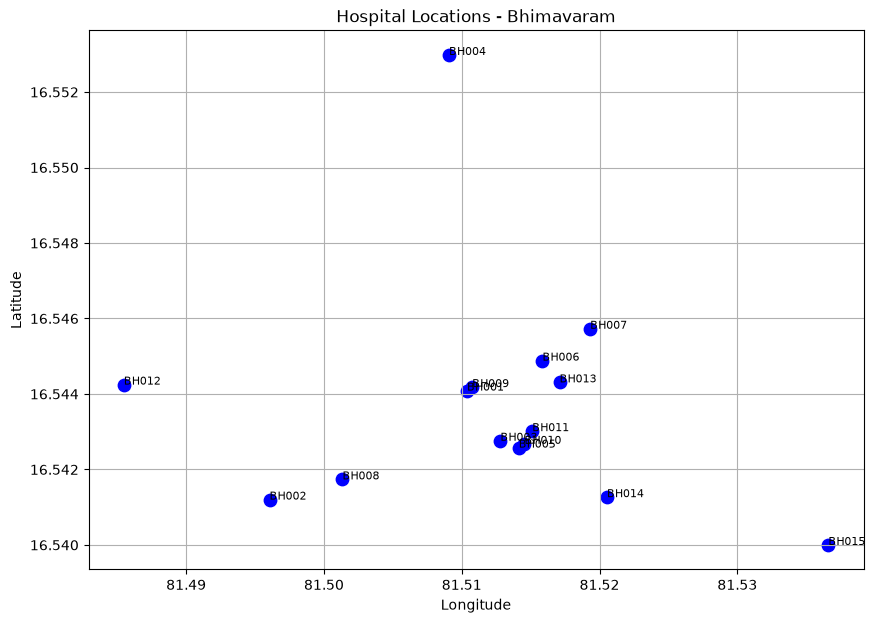

In [48]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

plt.scatter(
    hospitals["lon"],
    hospitals["lat"],
    color="blue",
    s=80
)

for _, row in hospitals.iterrows():
    plt.text(
        row["lon"],
        row["lat"],
        row["hosp_id"],
        fontsize=8
    )

plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Hospital Locations - Bhimavaram")
plt.grid(True)
plt.show()

In [49]:
#Haversine formula--to calculate approximate straight-line distance between two geographical coordinates 
from math import radians, sin, cos, sqrt, atan2

# Bhimavaram reference coordinates
center_lat = 16.54588378517661
center_lon = 81.51918504220544

def calculate_distance(lat1, lon1, lat2, lon2):
    R = 6371  # Earth's radius in km

    lat1, lon1, lat2, lon2 = map(
        radians, [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = sin(dlat/2)**2 + cos(lat1) * cos(lat2) * sin(dlon/2)**2
    c = 2 * atan2(sqrt(a), sqrt(1-a))

    return R * c

hospitals["distance_from_center_km"] = hospitals.apply(
    lambda row: calculate_distance(
        center_lat, center_lon,
        row["lat"], row["lon"]
    ),
    axis=1
)

hospitals["within_15km"] = (
    hospitals["distance_from_center_km"] <= 15
)

display(
    hospitals[[
        "hosp_id", "facility",
        "distance_from_center_km", "within_15km"
    ]].sort_values("distance_from_center_km")
)

,hosp_id,facility,distance_from_center_km,within_15km
6,BH007,Sri Lakshmi Hospitals,0.022807,True
12,BH013,Gift Fertility & Neuro Hospital,0.283047,True
5,BH006,Vinayaka Hospital,0.371548,True
13,BH014,Area Hospital - Bhimavaram,0.533406,True
10,BH011,Sai Indian Hospitals,0.538314,True
9,BH010,"Motherness Fertility, Women & Children's Hospital",0.609044,True
4,BH005,Nallaparaju Venkata Raju (NVR) Hospital,0.651264,True
2,BH003,Imperial Hospitals,0.763294,True
8,BH009,R.K. Gayathri Hospital,0.917939,True
0,BH001,Varma Hospitals,0.958998,True


In [50]:
print("Total service records:", len(services))

print("\nServices available:")
print(services["service"].value_counts())

print("\nEvidence categories:")
print(services["evidence"].value_counts())

Total service records: 66

Services available:
service
Unknown - needs verification    9
General Medicine                5
Orthopedics                     5
Urology                         4
Neurosurgery                    4
General Surgery                 4
Pediatrics                      4
OBG                             4
Cardiology                      3
Nephrology                      3
ENT                             3
Pulmonology                     3
Gynaecology                     2
Cardiothoracic Surgery          1
Radiology                       1
Neurology                       1
Plastic Surgery                 1
Gastroenterology                1
Psychiatry                      1
Dermatology                     1
Rheumatology                    1
Endocrinology                   1
Surgical Gastroenterology       1
Critical Care                   1
Trauma care                     1
Obstetrics                      1
Name: count, dtype: int64

Evidence categories:
evidence
Publ

In [51]:
#Hospital-wise services 
hospital_service_summary = services.groupby("hosp_id").agg(
    total_services=("service", "count"),
    services_list=("service", lambda x: ", ".join(x))
).reset_index()

display(hospital_service_summary)


,hosp_id,total_services,services_list
0,BH001,13,"Cardiology, Cardiothoracic Surgery, Urology, N..."
1,BH002,17,"Cardiology, Nephrology, Urology, Neurology, Ne..."
2,BH003,9,"General Medicine, General Surgery, Orthopedics..."
3,BH004,9,"Orthopedics, Neurosurgery, General Surgery, Ge..."
4,BH005,7,"General Medicine, Obstetrics, Gynaecology, Uro..."
5,BH006,1,Unknown - needs verification
6,BH007,1,Unknown - needs verification
7,BH008,1,Unknown - needs verification
8,BH009,1,Unknown - needs verification
9,BH010,1,Unknown - needs verification


In [52]:
print("Emergency Types:")
print(scenarios["emergency"].value_counts())

Emergency Types:
emergency
Chest_Pain                49
General_Medical           47
Pregnancy_Complication    45
Road_Trauma               42
Child_Emergency           40
Breathing_Difficulty      40
Stroke_Suspected          37
Name: count, dtype: int64


In [53]:
emergency_service_mapping = {
    "Chest_Pain": ["Cardiology"],

    "General_Medical": ["General Medicine"],

    "Pregnancy_Complication": [
        "OBG", "Gynaecology", "Obstetrics"
    ],

    "Road_Trauma": [
        "Orthopedics", "General Surgery"
    ],

    "Child_Emergency": ["Pediatrics"],

    "Breathing_Difficulty": ["Pulmonology"],

    "Stroke_Suspected": [
        "Neurology", "Neurosurgery"
    ]
}
for emergency, required_services in emergency_service_mapping.items():
    print(emergency, "->", required_services)

Chest_Pain -> ['Cardiology']
General_Medical -> ['General Medicine']
Pregnancy_Complication -> ['OBG', 'Gynaecology', 'Obstetrics']
Road_Trauma -> ['Orthopedics', 'General Surgery']
Child_Emergency -> ['Pediatrics']
Breathing_Difficulty -> ['Pulmonology']
Stroke_Suspected -> ['Neurology', 'Neurosurgery']


In [54]:
def find_matching_hospitals(emergency_type):

    required_services = emergency_service_mapping[emergency_type]

    matching = services[
        services["service"].isin(required_services)
    ]

    hospital_ids = matching["hosp_id"].unique()

    return hospital_ids
result = find_matching_hospitals("Chest_Pain")

print("Matching Hospitals:")
print(result)

Matching Hospitals:
<StringArray>
['BH001', 'BH002', 'BH003']
Length: 3, dtype: str


In [55]:
for emergency in emergency_service_mapping:

    result = find_matching_hospitals(emergency)

    print("\nEmergency:", emergency)
    print("Matching Hospitals:", list(result))
    print("Total Matches:", len(result))


Emergency: Chest_Pain
Matching Hospitals: ['BH001', 'BH002', 'BH003']
Total Matches: 3

Emergency: General_Medical
Matching Hospitals: ['BH001', 'BH002', 'BH003', 'BH004', 'BH005']
Total Matches: 5

Emergency: Pregnancy_Complication
Matching Hospitals: ['BH001', 'BH002', 'BH003', 'BH004', 'BH005', 'BH011']
Total Matches: 6

Emergency: Road_Trauma
Matching Hospitals: ['BH001', 'BH002', 'BH003', 'BH004', 'BH005']
Total Matches: 5

Emergency: Child_Emergency
Matching Hospitals: ['BH001', 'BH002', 'BH003', 'BH011']
Total Matches: 4

Emergency: Breathing_Difficulty
Matching Hospitals: ['BH001', 'BH002', 'BH003']
Total Matches: 3

Emergency: Stroke_Suspected
Matching Hospitals: ['BH001', 'BH002', 'BH003', 'BH004']
Total Matches: 4


In [57]:
def get_hospital_recommendations(emergency_type):

    required_services = emergency_service_mapping[emergency_type]

    # Find hospitals with publicly listed matching services
    matching = services[
        (services["service"].isin(required_services)) &
        (services["evidence"] == "Publicly listed")
    ]

    # Get matching hospital IDs
    matching_ids = matching["hosp_id"].unique()

    # Find hospitals needing service verification
    unknown_ids = services[
        services["service"] == "Unknown - needs verification"
    ]["hosp_id"].unique()

    # Avoid duplicate hospitals
    unknown_ids = [
        hid for hid in unknown_ids if hid not in matching_ids
    ]

    # Get hospital details
    matching_details = hospitals[
        hospitals["hosp_id"].isin(matching_ids)
    ]

    return matching_details, unknown_ids

In [58]:
for emergency in emergency_service_mapping:

    matching_details, unknown_ids = get_hospital_recommendations(emergency)

    print("\n" + "=" * 50)
    print("Emergency Type:", emergency)

    print("\nMatching Hospitals:")
    display(matching_details[["hosp_id", "facility"]])

    print("Hospitals Needing Verification:")
    print(unknown_ids)

    print("Total Matching Hospitals:", len(matching_details))
    print("Total Hospitals Needing Verification:", len(unknown_ids))


Emergency Type: Chest_Pain

Matching Hospitals:


,hosp_id,facility
0,BH001,Varma Hospitals
1,BH002,Bhimavaram Hospitals Ltd.
2,BH003,Imperial Hospitals


Hospitals Needing Verification:
['BH006', 'BH007', 'BH008', 'BH009', 'BH010', 'BH012', 'BH013', 'BH014', 'BH015']
Total Matching Hospitals: 3
Total Hospitals Needing Verification: 9

Emergency Type: General_Medical

Matching Hospitals:


,hosp_id,facility
0,BH001,Varma Hospitals
1,BH002,Bhimavaram Hospitals Ltd.
2,BH003,Imperial Hospitals
3,BH004,Rajarshi Hospitals - Bhimavaram
4,BH005,Nallaparaju Venkata Raju (NVR) Hospital


Hospitals Needing Verification:
['BH006', 'BH007', 'BH008', 'BH009', 'BH010', 'BH012', 'BH013', 'BH014', 'BH015']
Total Matching Hospitals: 5
Total Hospitals Needing Verification: 9

Emergency Type: Pregnancy_Complication

Matching Hospitals:


,hosp_id,facility
0,BH001,Varma Hospitals
1,BH002,Bhimavaram Hospitals Ltd.
2,BH003,Imperial Hospitals
3,BH004,Rajarshi Hospitals - Bhimavaram
4,BH005,Nallaparaju Venkata Raju (NVR) Hospital
10,BH011,Sai Indian Hospitals


... (5 outputs left out)

,hosp_id,facility
0,BH001,Varma Hospitals
1,BH002,Bhimavaram Hospitals Ltd.
2,BH003,Imperial Hospitals


Hospitals Needing Verification:
['BH006', 'BH007', 'BH008', 'BH009', 'BH010', 'BH012', 'BH013', 'BH014', 'BH015']
Total Matching Hospitals: 3
Total Hospitals Needing Verification: 9

Emergency Type: Stroke_Suspected

Matching Hospitals:


,hosp_id,facility
0,BH001,Varma Hospitals
1,BH002,Bhimavaram Hospitals Ltd.
2,BH003,Imperial Hospitals
3,BH004,Rajarshi Hospitals - Bhimavaram


Hospitals Needing Verification:
['BH006', 'BH007', 'BH008', 'BH009', 'BH010', 'BH012', 'BH013', 'BH014', 'BH015']
Total Matching Hospitals: 4
Total Hospitals Needing Verification: 9


In [59]:
# Get matching hospitals for Chest Pain
matching_details, unknown_ids = get_hospital_recommendations("Chest_Pain")

# Sort hospitals based on distance
ranked_hospitals = matching_details.sort_values(
    by="distance_from_center_km",
    ascending=True
).copy()

# Assign ranks
ranked_hospitals["rank"] = range(1, len(ranked_hospitals) + 1)

# Display ranked hospitals
display(
    ranked_hospitals[
        ["rank", "hosp_id", "facility", "distance_from_center_km"]
    ]
)

,rank,hosp_id,facility,distance_from_center_km
2,1,BH003,Imperial Hospitals,0.763294
0,2,BH001,Varma Hospitals,0.958998
1,3,BH002,Bhimavaram Hospitals Ltd.,2.520248


In [60]:
def rank_hospitals(emergency_type):

    # Step 1: Get matching hospitals
    matching_details, unknown_ids = get_hospital_recommendations(
        emergency_type
    )

    # Step 2: Sort hospitals by distance
    ranked_hospitals = matching_details.sort_values(
        by="distance_from_center_km",
        ascending=True
    ).copy()

    # Step 3: Assign ranks
    ranked_hospitals["rank"] = range(
        1, len(ranked_hospitals) + 1
    )

    # Step 4: Return results
    return ranked_hospitals, unknown_ids

In [61]:
for emergency in emergency_service_mapping:

    ranked_hospitals, unknown_ids = rank_hospitals(emergency)

    print("\n" + "=" * 60)
    print("EMERGENCY TYPE:", emergency)

    print("\nRANKED HOSPITALS:")

    display(
        ranked_hospitals[
            [
                "rank",
                "hosp_id",
                "facility",
                "distance_from_center_km"
            ]
        ]
    )

    print("Hospitals Needing Verification:", list(unknown_ids))


EMERGENCY TYPE: Chest_Pain

RANKED HOSPITALS:


,rank,hosp_id,facility,distance_from_center_km
2,1,BH003,Imperial Hospitals,0.763294
0,2,BH001,Varma Hospitals,0.958998
1,3,BH002,Bhimavaram Hospitals Ltd.,2.520248


Hospitals Needing Verification: ['BH006', 'BH007', 'BH008', 'BH009', 'BH010', 'BH012', 'BH013', 'BH014', 'BH015']

EMERGENCY TYPE: General_Medical

RANKED HOSPITALS:


,rank,hosp_id,facility,distance_from_center_km
4,1,BH005,Nallaparaju Venkata Raju (NVR) Hospital,0.651264
2,2,BH003,Imperial Hospitals,0.763294
0,3,BH001,Varma Hospitals,0.958998
3,4,BH004,Rajarshi Hospitals - Bhimavaram,1.335483
1,5,BH002,Bhimavaram Hospitals Ltd.,2.520248


Hospitals Needing Verification: ['BH006', 'BH007', 'BH008', 'BH009', 'BH010', 'BH012', 'BH013', 'BH014', 'BH015']

EMERGENCY TYPE: Pregnancy_Complication

RANKED HOSPITALS:


,rank,hosp_id,facility,distance_from_center_km
10,1,BH011,Sai Indian Hospitals,0.538314
4,2,BH005,Nallaparaju Venkata Raju (NVR) Hospital,0.651264
2,3,BH003,Imperial Hospitals,0.763294
0,4,BH001,Varma Hospitals,0.958998
3,5,BH004,Rajarshi Hospitals - Bhimavaram,1.335483
1,6,BH002,Bhimavaram Hospitals Ltd.,2.520248


... (5 outputs left out)

,rank,hosp_id,facility,distance_from_center_km
2,1,BH003,Imperial Hospitals,0.763294
0,2,BH001,Varma Hospitals,0.958998
1,3,BH002,Bhimavaram Hospitals Ltd.,2.520248


Hospitals Needing Verification: ['BH006', 'BH007', 'BH008', 'BH009', 'BH010', 'BH012', 'BH013', 'BH014', 'BH015']

EMERGENCY TYPE: Stroke_Suspected

RANKED HOSPITALS:


,rank,hosp_id,facility,distance_from_center_km
2,1,BH003,Imperial Hospitals,0.763294
0,2,BH001,Varma Hospitals,0.958998
3,3,BH004,Rajarshi Hospitals - Bhimavaram,1.335483
1,4,BH002,Bhimavaram Hospitals Ltd.,2.520248


Hospitals Needing Verification: ['BH006', 'BH007', 'BH008', 'BH009', 'BH010', 'BH012', 'BH013', 'BH014', 'BH015']


In [63]:
%pip install requests

  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
  Using cached charset_normalizer-3.5.2-cp314-cp314-win_amd64.whl.metadata (47 kB)
  Using cached idna-3.20-py3-none-any.whl.metadata (7.2 kB)
  Using cached urllib3-2.8.0-py3-none-any.whl.metadata (7.4 kB)
  Using cached certifi-2026.10.23-py3-none-any.whl.metadata (2.5 kB)
Using cached requests-2.34.2-py3-none-any.whl (73 kB)
Using cached charset_normalizer-3.5.2-cp314-cp314-win_amd64.whl (210 kB)
Using cached idna-3.20-py3-none-any.whl (69 kB)
Using cached urllib3-2.8.0-py3-none-any.whl (135 kB)
Using cached certifi-2026.10.23-py3-none-any.whl (135 kB)

   ---------------------------------------- 0/5 [urllib3]
   ---------------------------------------- 0/5 [urllib3]
   ---------------------------------------- 0/5 [urllib3]
   ---------------------------------------- 0/5 [urllib3]
   ---------------------------------------- 0/5 [urllib3]
   ---------------------------------------- 0/5 [urllib3]
   --------------------


[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [64]:
import requests

# Emergency location (temporary reference point)
origin_lat = 16.54588378517661
origin_lon = 81.51918504220544

# Varma Hospitals coordinates
destination_lat = 16.5440896
destination_lon = 81.5103849

# OSRM routing URL
url = (
    f"https://router.project-osrm.org/route/v1/driving/"
    f"{origin_lon},{origin_lat};{destination_lon},{destination_lat}"
    f"?overview=false"
)

# Send request
response = requests.get(url)

# Convert response into JSON
route_data = response.json()

# Extract distance and duration
if route_data["code"] == "Ok":

    distance_km = route_data["routes"][0]["distance"] / 1000

    travel_time_min = route_data["routes"][0]["duration"] / 60

    print("Road Distance:", round(distance_km, 2), "km")
    print("Estimated Travel Time:", round(travel_time_min, 2), "minutes")

else:
    print("Route not found:", route_data["code"])

Road Distance: 1.27 km
Estimated Travel Time: 2.75 minutes


In [65]:
import requests
import time

origin_lat = 16.54588378517661
origin_lon = 81.51918504220544

road_distances = []
travel_times = []

for index, row in hospitals.iterrows():

    destination_lat = row["lat"]
    destination_lon = row["lon"]

    url = (
        f"https://router.project-osrm.org/route/v1/driving/"
        f"{origin_lon},{origin_lat};{destination_lon},{destination_lat}"
        f"?overview=false"
    )

    try:
        response = requests.get(url, timeout=20)
        route_data = response.json()

        if route_data["code"] == "Ok":

            distance_km = route_data["routes"][0]["distance"] / 1000
            travel_time_min = route_data["routes"][0]["duration"] / 60

            road_distances.append(distance_km)
            travel_times.append(travel_time_min)

        else:
            road_distances.append(None)
            travel_times.append(None)

    except Exception:
        road_distances.append(None)
        travel_times.append(None)

    time.sleep(1)

hospitals["road_distance_km"] = road_distances
hospitals["travel_time_min"] = travel_times

display(
    hospitals[
        ["hosp_id", "facility", "road_distance_km", "travel_time_min"]
    ]
)

,hosp_id,facility,road_distance_km,travel_time_min
0,BH001,Varma Hospitals,1.2716,2.753333
1,BH002,Bhimavaram Hospitals Ltd.,2.7906,5.866667
2,BH003,Imperial Hospitals,0.8672,1.938333
3,BH004,Rajarshi Hospitals - Bhimavaram,1.4302,1.231667
4,BH005,Nallaparaju Venkata Raju (NVR) Hospital,0.7889,1.818333
5,BH006,Vinayaka Hospital,0.6984,1.381667
6,BH007,Sri Lakshmi Hospitals,0.0134,0.033333
7,BH008,Akshara Speciality Hospitals,2.1207,4.055000
8,BH009,R.K. Gayathri Hospital,1.1219,2.273333
9,BH010,"Motherness Fertility, Women & Children's Hospital",0.7683,1.821667


In [66]:
def rank_hospitals_by_eta(emergency_type):

    # Step 1: Find matching hospitals
    matching_details, unknown_ids = get_hospital_recommendations(
        emergency_type
    )

    # Step 2: Remove hospitals without route information
    matching_details = matching_details.dropna(
        subset=["travel_time_min"]
    ).copy()

    # Step 3: Sort by estimated travel time
    ranked_hospitals = matching_details.sort_values(
        by=["travel_time_min", "road_distance_km"],
        ascending=True
    ).copy()

    # Step 4: Assign ranks
    ranked_hospitals["rank"] = range(
        1, len(ranked_hospitals) + 1
    )

    # Step 5: Return results
    return ranked_hospitals, unknown_ids

In [67]:
ranked_hospitals, unknown_ids = rank_hospitals_by_eta("Chest_Pain")

print("CHEST PAIN - ETA BASED HOSPITAL RANKING")

display(
    ranked_hospitals[
        [
            "rank",
            "hosp_id",
            "facility",
            "road_distance_km",
            "travel_time_min"
        ]
    ]
)

print("Hospitals Needing Verification:", list(unknown_ids))

CHEST PAIN - ETA BASED HOSPITAL RANKING


,rank,hosp_id,facility,road_distance_km,travel_time_min
2,1,BH003,Imperial Hospitals,0.8672,1.938333
0,2,BH001,Varma Hospitals,1.2716,2.753333
1,3,BH002,Bhimavaram Hospitals Ltd.,2.7906,5.866667


Hospitals Needing Verification: ['BH006', 'BH007', 'BH008', 'BH009', 'BH010', 'BH012', 'BH013', 'BH014', 'BH015']


In [68]:
for emergency in emergency_service_mapping:

    ranked_hospitals, unknown_ids = rank_hospitals_by_eta(emergency)

    print("\n" + "=" * 60)
    print("EMERGENCY TYPE:", emergency)

    display(
        ranked_hospitals[
            [
                "rank",
                "hosp_id",
                "facility",
                "road_distance_km",
                "travel_time_min"
            ]
        ]
    )

    print("Hospitals Needing Verification:", list(unknown_ids))


EMERGENCY TYPE: Chest_Pain


,rank,hosp_id,facility,road_distance_km,travel_time_min
2,1,BH003,Imperial Hospitals,0.8672,1.938333
0,2,BH001,Varma Hospitals,1.2716,2.753333
1,3,BH002,Bhimavaram Hospitals Ltd.,2.7906,5.866667


Hospitals Needing Verification: ['BH006', 'BH007', 'BH008', 'BH009', 'BH010', 'BH012', 'BH013', 'BH014', 'BH015']

EMERGENCY TYPE: General_Medical


,rank,hosp_id,facility,road_distance_km,travel_time_min
3,1,BH004,Rajarshi Hospitals - Bhimavaram,1.4302,1.231667
4,2,BH005,Nallaparaju Venkata Raju (NVR) Hospital,0.7889,1.818333
2,3,BH003,Imperial Hospitals,0.8672,1.938333
0,4,BH001,Varma Hospitals,1.2716,2.753333
1,5,BH002,Bhimavaram Hospitals Ltd.,2.7906,5.866667


Hospitals Needing Verification: ['BH006', 'BH007', 'BH008', 'BH009', 'BH010', 'BH012', 'BH013', 'BH014', 'BH015']

EMERGENCY TYPE: Pregnancy_Complication


,rank,hosp_id,facility,road_distance_km,travel_time_min
3,1,BH004,Rajarshi Hospitals - Bhimavaram,1.4302,1.231667
10,2,BH011,Sai Indian Hospitals,0.6549,1.558333
4,3,BH005,Nallaparaju Venkata Raju (NVR) Hospital,0.7889,1.818333
2,4,BH003,Imperial Hospitals,0.8672,1.938333
0,5,BH001,Varma Hospitals,1.2716,2.753333
1,6,BH002,Bhimavaram Hospitals Ltd.,2.7906,5.866667


... (5 outputs left out)

,rank,hosp_id,facility,road_distance_km,travel_time_min
2,1,BH003,Imperial Hospitals,0.8672,1.938333
0,2,BH001,Varma Hospitals,1.2716,2.753333
1,3,BH002,Bhimavaram Hospitals Ltd.,2.7906,5.866667


Hospitals Needing Verification: ['BH006', 'BH007', 'BH008', 'BH009', 'BH010', 'BH012', 'BH013', 'BH014', 'BH015']

EMERGENCY TYPE: Stroke_Suspected


,rank,hosp_id,facility,road_distance_km,travel_time_min
3,1,BH004,Rajarshi Hospitals - Bhimavaram,1.4302,1.231667
2,2,BH003,Imperial Hospitals,0.8672,1.938333
0,3,BH001,Varma Hospitals,1.2716,2.753333
1,4,BH002,Bhimavaram Hospitals Ltd.,2.7906,5.866667


Hospitals Needing Verification: ['BH006', 'BH007', 'BH008', 'BH009', 'BH010', 'BH012', 'BH013', 'BH014', 'BH015']


In [69]:
def recommend_top_hospitals(emergency_type):

    ranked_hospitals, unknown_ids = rank_hospitals_by_eta(
        emergency_type
    )

    # Select top 3 hospitals
    top_hospitals = ranked_hospitals.head(3)

    return top_hospitals, unknown_ids

In [70]:
top_hospitals, unknown_ids = recommend_top_hospitals("Chest_Pain")

print("EMERGENCY: CHEST PAIN")
print("\nTOP 3 RECOMMENDED HOSPITALS")

display(
    top_hospitals[
        [
            "rank",
            "hosp_id",
            "facility",
            "road_distance_km",
            "travel_time_min"
        ]
    ]
)

print("\nHOSPITALS NEEDING SERVICE VERIFICATION:")
print(unknown_ids)

EMERGENCY: CHEST PAIN

TOP 3 RECOMMENDED HOSPITALS


,rank,hosp_id,facility,road_distance_km,travel_time_min
2,1,BH003,Imperial Hospitals,0.8672,1.938333
0,2,BH001,Varma Hospitals,1.2716,2.753333
1,3,BH002,Bhimavaram Hospitals Ltd.,2.7906,5.866667



HOSPITALS NEEDING SERVICE VERIFICATION:
['BH006', 'BH007', 'BH008', 'BH009', 'BH010', 'BH012', 'BH013', 'BH014', 'BH015']


In [76]:
top_hospitals, unknown_ids = recommend_top_hospitals(
    "Pregnancy_Complication"
)

display(
    top_hospitals[
        [
            "rank",
            "hosp_id",
            "facility",
            "road_distance_km",
            "travel_time_min"
        ]
    ]
)

,rank,hosp_id,facility,road_distance_km,travel_time_min
3,1,BH004,Rajarshi Hospitals - Bhimavaram,1.4302,1.231667
10,2,BH011,Sai Indian Hospitals,0.6549,1.558333
4,3,BH005,Nallaparaju Venkata Raju (NVR) Hospital,0.7889,1.818333


In [81]:
location = input("Enter latitude,longitude: ")

print("You entered:", repr(location))

try:
    coordinates = location.strip().split(",")

    if len(coordinates) != 2:
        print("Please enter exactly two values separated by comma.")

    else:
        origin_lat = float(coordinates[0].strip())
        origin_lon = float(coordinates[1].strip())

        print("Latitude:", origin_lat)
        print("Longitude:", origin_lon)
        print("Location received successfully!")

except ValueError:
    print("Invalid input! Enter decimal coordinates only.")

You entered: '16.54588378517661,81.51918504220544'
Latitude: 16.54588378517661
Longitude: 81.51918504220544
Location received successfully!


In [84]:
def dynamic_hospital_ranking(emergency_type, hospital_routes):

    matching_details, unknown_ids = get_hospital_recommendations(
        emergency_type
    )

    matching_details = matching_details[
        ["hosp_id", "facility"]
    ].merge(
        hospital_routes[
            ["hosp_id", "road_distance_km", "travel_time_min"]
        ],
        on="hosp_id",
        how="left"
    )

    matching_details = matching_details.dropna(
        subset=["travel_time_min"]
    )

    ranked_hospitals = matching_details.sort_values(
        by=["travel_time_min", "road_distance_km"],
        ascending=True
    ).copy()

    ranked_hospitals["rank"] = range(
        1, len(ranked_hospitals) + 1
    )

    return ranked_hospitals, unknown_ids

In [85]:
ranked_hospitals, unknown_ids = dynamic_hospital_ranking(
    "Chest_Pain",
    hospital_routes
)

display(
    ranked_hospitals[
        ["rank", "hosp_id", "facility",
         "road_distance_km", "travel_time_min"]
    ].head(3)
)

print("Hospitals needing verification:", unknown_ids)

,rank,hosp_id,facility,road_distance_km,travel_time_min
2,1,BH003,Imperial Hospitals,0.8672,1.938333
0,2,BH001,Varma Hospitals,1.2716,2.753333
1,3,BH002,Bhimavaram Hospitals Ltd.,2.7906,5.866667


Hospitals needing verification: ['BH006', 'BH007', 'BH008', 'BH009', 'BH010', 'BH012', 'BH013', 'BH014', 'BH015']


In [86]:
print("AVAILABLE EMERGENCY TYPES")

for i, emergency in enumerate(emergency_service_mapping.keys(), start=1):
    print(i, ".", emergency)

choice = int(input("\nSelect Emergency Type (1-7): "))

emergency_types = list(emergency_service_mapping.keys())

if 1 <= choice <= len(emergency_types):
    selected_emergency = emergency_types[choice - 1]
    print("\nSelected Emergency:", selected_emergency)
else:
    print("Invalid choice!")

AVAILABLE EMERGENCY TYPES
1 . Chest_Pain
2 . General_Medical
3 . Pregnancy_Complication
4 . Road_Trauma
5 . Child_Emergency
6 . Breathing_Difficulty
7 . Stroke_Suspected

Selected Emergency: General_Medical


In [89]:
ranked_hospitals, unknown_ids = dynamic_hospital_ranking(
    selected_emergency,
    hospital_routes
)

top_3_hospitals = ranked_hospitals.head(3)

display(
    top_3_hospitals[
        ["rank", "hosp_id", "facility",
         "road_distance_km", "travel_time_min"]
    ]
)

print("Hospitals needing verification:", unknown_ids)

,rank,hosp_id,facility,road_distance_km,travel_time_min
3,1,BH004,Rajarshi Hospitals - Bhimavaram,1.4302,1.231667
4,2,BH005,Nallaparaju Venkata Raju (NVR) Hospital,0.7889,1.818333
2,3,BH003,Imperial Hospitals,0.8672,1.938333


Hospitals needing verification: ['BH006', 'BH007', 'BH008', 'BH009', 'BH010', 'BH012', 'BH013', 'BH014', 'BH015']
